# Project 1: ResNet under 5M parameters on CIFAR-10
Mirsaid Abbasov (ma9197), NYU Deep Learning, Fall 2026. Solo project.

This notebook loads the trained models and logs produced by `train.py`, prints the parameter count and the final test accuracy, plots the training curves, compares the experiments, and writes the Kaggle submission.

Reproduce the final model (about 32 min on one RTX 4090 Laptop GPU):
```
python train.py --name final_B_ta_e200 --channels 84 168 336 --blocks 2 2 2 --epochs 200 --trivialaug --full-train
python predict.py --run final_B_ta_e200
```

In [1]:
import json, csv
from pathlib import Path
import numpy as np, torch
import matplotlib.pyplot as plt
from torchsummary import summary
from train import ResNet, count_params, load_cifar, evaluate
FINAL = 'final_B_ta_e200'
print(torch.__version__, torch.cuda.get_device_name())

2.6.0+cu124 NVIDIA GeForce RTX 4090 Laptop GPU


## Final model: architecture and number of parameters

In [2]:
ck = torch.load(f'runs/{FINAL}/model.pt', map_location='cuda', weights_only=False)
a = ck['args']
model = ResNet(a['channels'], a['blocks'], a['kernel'], a['skip_kernel']).cuda()
model.load_state_dict(ck['model']); model.eval()
summary(model, (3, 32, 32))
n = count_params(model)
print(f'Trainable parameters: {n:,}  (limit 5,000,000)')
assert n <= 5_000_000

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 84, 32, 32]           2,268
       BatchNorm2d-2           [-1, 84, 32, 32]             168
              ReLU-3           [-1, 84, 32, 32]               0
            Conv2d-4           [-1, 84, 32, 32]          63,504
       BatchNorm2d-5           [-1, 84, 32, 32]             168
            Conv2d-6           [-1, 84, 32, 32]          63,504
       BatchNorm2d-7           [-1, 84, 32, 32]             168
          Identity-8           [-1, 84, 32, 32]               0
        BasicBlock-9           [-1, 84, 32, 32]               0
           Conv2d-10           [-1, 84, 32, 32]          63,504
      BatchNorm2d-11           [-1, 84, 32, 32]             168
           Conv2d-12           [-1, 84, 32, 32]          63,504
      BatchNorm2d-13           [-1, 84, 32, 32]             168
         Identity-14           [-1, 84,

## Final test accuracy (standard CIFAR-10 test set, 10,000 images)

In [3]:
xtr, ytr, xte, yte = load_cifar('cuda')
loss, acc = evaluate(model, xte, yte)
_, acc_tta = evaluate(model, xte, yte, tta=True)
print(f'CIFAR-10 test accuracy: {100*acc:.2f}%   (with horizontal-flip TTA: {100*acc_tta:.2f}%)')

CIFAR-10 test accuracy: 96.73%   (with horizontal-flip TTA: 97.00%)


## Training curves (200 epochs, with and without TrivialAugment)

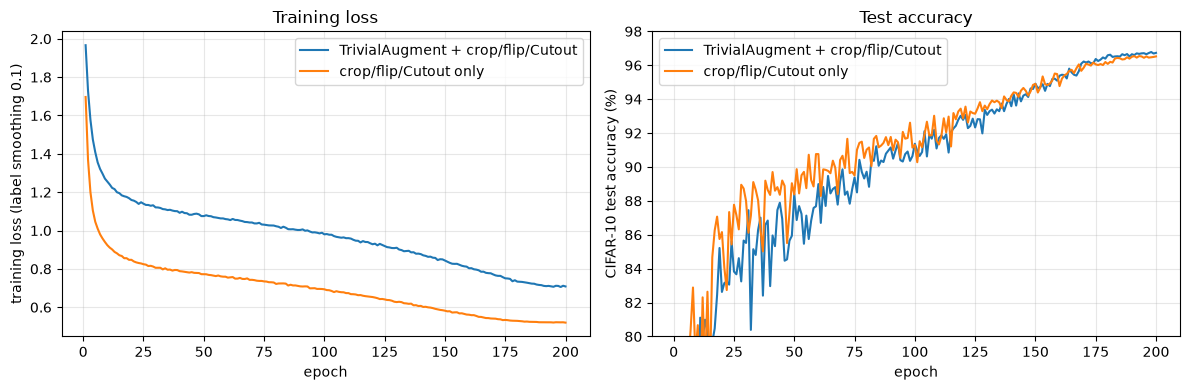

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for run, lab in [('final_B_ta_e200', 'TrivialAugment + crop/flip/Cutout'), ('final_B_base_e200', 'crop/flip/Cutout only')]:
    log = json.loads(Path(f'runs/{run}/log.json').read_text())
    ep = [r['epoch'] for r in log]
    ax[0].plot(ep, [r['train_loss'] for r in log], label=lab)
    ax[1].plot(ep, [100*r['val_acc'] for r in log], label=lab)
ax[0].set(xlabel='epoch', ylabel='training loss (label smoothing 0.1)', title='Training loss')
ax[1].set(xlabel='epoch', ylabel='CIFAR-10 test accuracy (%)', title='Test accuracy', ylim=(80, 98))
for x in ax: x.grid(alpha=0.3); x.legend()
plt.tight_layout(); plt.savefig('figures/curves.png', dpi=160); plt.show()

## All experiments

In [5]:
rows = []
for s in sorted(Path('runs').glob('*/summary.json')):
    d = json.loads(s.read_text())
    rows.append((d['name'], d['params'], d['channels'], d['blocks'], d['epochs'], d['args'].get('trivialaug', False),
                 100*d['cifar10_test_acc'], 100*d['cifar10_test_acc_flipTTA'], d['minutes']))
print(f"{'run':20s} {'params':>10s} {'channels':16s} {'blocks':10s} {'ep':>4s} {'TA':>5s} {'test':>7s} {'+TTA':>7s} {'min':>5s}")
for r in rows:
    print(f'{r[0]:20s} {r[1]:>10,} {str(r[2]):16s} {str(r[3]):10s} {r[4]:>4d} {str(r[5]):>5s} {r[6]:6.2f}% {r[7]:6.2f}% {r[8]:5.1f}')

run                      params channels         blocks       ep    TA    test    +TTA   min
e50_B_base            4,781,374 [84, 168, 336]   [2, 2, 2]    50 False  95.41%  95.68%   7.2
e50_B_ta              4,781,374 [84, 168, 336]   [2, 2, 2]    50  True  94.80%  95.18%   7.2
final_B_base_e200     4,781,374 [84, 168, 336]   [2, 2, 2]   200 False  96.52%  96.83%  32.2
final_B_ta_e200       4,781,374 [84, 168, 336]   [2, 2, 2]   200  True  96.73%  97.00%  32.4
pilot_A               4,327,754 [64, 128, 256]   [3, 3, 3]    15 False  91.68%  92.21%   2.2
pilot_B               4,781,374 [84, 168, 336]   [2, 2, 2]    15 False  92.39%  92.59%   2.3
pilot_C               4,903,242 [64, 128, 256, 512] [1, 1, 1, 1]   15 False  89.98%  90.34%   1.4
pilot_D               4,521,034 [64, 128, 256, 320] [2, 2, 2, 1]   15 False  91.48%  91.86%   1.8


## Per-class accuracy of the final model

airplane     96.80%
automobile   98.80%
bird         95.80%
cat          92.80%
deer         98.10%
dog          95.10%
frog         98.40%
horse        97.50%
ship         98.50%
truck        98.00%


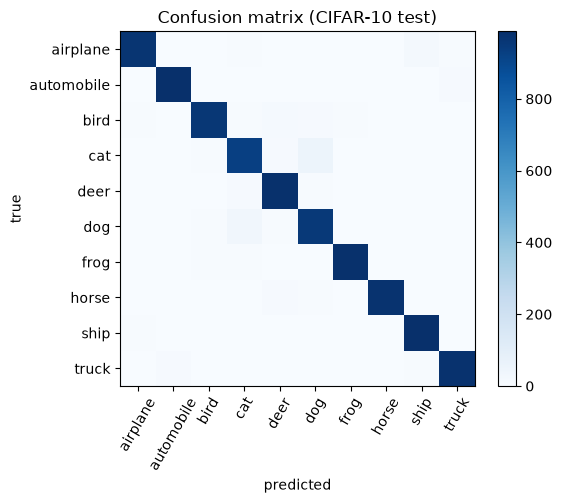

In [6]:
with torch.no_grad():
    from train import normalize
    preds = []
    for k in range(0, 10000, 1000):
        xb = normalize(xte[k:k+1000])
        with torch.autocast('cuda', dtype=torch.bfloat16):
            o = model(xb).float().softmax(1) + model(xb.flip(3)).float().softmax(1)
        preds.append(o.argmax(1))
preds = torch.cat(preds).cpu().numpy(); y = yte.cpu().numpy()
classes = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
cm = np.zeros((10, 10), int)
for t, p in zip(y, preds): cm[t, p] += 1
for i, c in enumerate(classes): print(f'{c:11s} {100*cm[i,i]/cm[i].sum():6.2f}%')
plt.figure(figsize=(6, 5)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xticks(range(10), classes, rotation=60); plt.yticks(range(10), classes)
plt.xlabel('predicted'); plt.ylabel('true'); plt.title('Confusion matrix (CIFAR-10 test)')
plt.tight_layout(); plt.savefig('figures/confusion.png', dpi=160); plt.show()

## Kaggle submission (2,000 held-out images, labels hidden)

In [7]:
import subprocess, sys
print(subprocess.run([sys.executable, 'predict.py', '--run', FINAL], capture_output=True, text=True).stdout)
sub = list(csv.DictReader(open(f'submissions/{FINAL}.csv')))
print(len(sub), 'rows; first rows:', sub[:3])

model final_B_ta_e200: 4,781,374 trainable parameters
wrote D:\Files\NYU\Simestirs\Simestr 4 Fall 2026\Deep Learning\Project1\submissions\final_B_ta_e200.csv | 2000 rows | predicted class counts: [167, 219, 209, 206, 200, 220, 176, 199, 204, 200]

2000 rows; first rows: [{'id': '0', 'label': '6'}, {'id': '1', 'label': '3'}, {'id': '2', 'label': '3'}]
